# Exercise SYOTOOL's redshift evolution and extinction properties

We will test SYOTOOL's handling of redshift and extinction using a QSO template.

## Imports:

In [1]:
import numpy as np
from syotools.models import Source #Camera, Telescope
from syotools.spectra import SpectralLibrary
import synphot as syn
import stsynphot as stsyn

import astropy.units as u

import matplotlib
from matplotlib import pyplot as plt
%matplotlib inline

import syotools
print(syotools.__version__)

1.4.9


## Define the source template

In [2]:
# Create the source
sed = Source()

# Configure the source
# Let's start with redshift of 0 and no extinction
# We'll set the spectrum to have an AB magnitude
# of 18 in the SDSS g filter
template = 'QSO'
mag = 18
bandpass = 'sdss,g'
redshift = 0
extinction = 0
sed.set_sed(template, mag, redshift, extinction, bandpass=bandpass)

## Plot the QSO Template for $z=0$, no extinction

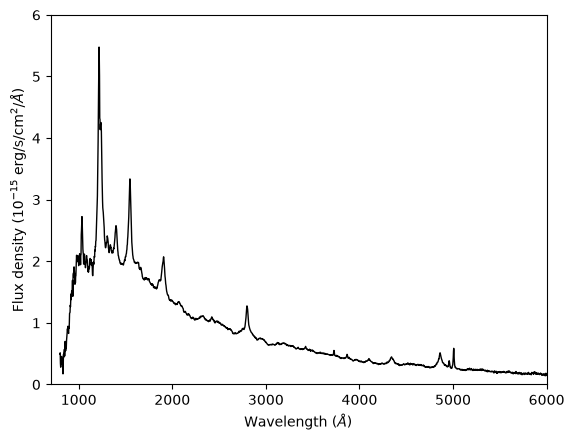

In [3]:
# Define flux array
qso_flux_rest = syn.units.convert_flux(sed.sed.waveset, sed.sed(sed.sed.waveset), syn.units.FLAM)
# Define wavelength array
qso_wave_rest = sed.sed.waveset
# Plot SED
plt.plot(qso_wave_rest.to_value(u.AA), qso_flux_rest.value*1e15, color='black',lw=1)

# Label axes
plt.xlabel(r'Wavelength ($\AA$)')
plt.ylabel(r'Flux density (10$^{-15}$ erg/s/cm$^2$/$\AA$)')

# Limit ranges on axes
plt.xlim(700,6000)
plt.ylim(0,6)

plt.show()

## Define some convenience functions to streamline comparison

Define the source SED in SYOTOOLS and normalize to flux density units. Return the wavelength axis in Angstrom units and the flux density axis in units of erg/s/cm^2/A. Return just the values of both arrays.

In [4]:
def syotools_flam(sed_in,template, mag, z, ext, bandpass):

    # Define the SED
    sed_in.set_sed(template, mag, z, ext, bandpass=bandpass)
    # Normalize to flux density units of erg/s/cm^2/A
    sed_flam = syn.units.convert_flux(sed_in.sed.waveset, sed_in.sed(sed_in.sed.waveset), syn.units.FLAM)

    return(sed.sed.waveset.to_value(u.AA), sed_flam.value)

Manually re-normalize an SED to flux density units. Assume that the SED has already been redshifted and any extinction has been applied.

In [5]:
def norm_sed(in_spectrum, bandpass, mag):

    # Define the bandpass for normalization
    bp = stsyn.spectrum.band(bandpass) 
    
    # Normalize input spectrum to specified magnitude
    norm_spec_ab = in_spectrum.normalize(mag * u.ABmag,bp)

    # Convert to flux density units
    norm_spec_flam = syn.units.convert_flux(in_spectrum.waveset, 
                                            norm_spec_ab(in_spectrum.waveset), 
                                            syn.units.FLAM)
    return(in_spectrum.waveset,norm_spec_flam.value)

## Redshift the source

In SYOTOOLS' native handling of redshifting a spectrum, it first redshifts the wavelength axis of the input SED. Then it normalizes the flux density axis to the normalization level specified in the given bandpass. In this case, the redshifted SED will be normalized to an `SDSS g-band` magnitude of 18.

Here we compare the redshifted spectrum derived through SYOTOOLs with the results from manually redshifting the SED. Do they agree?

We do this test for a handful of redshifts from $0 < z < 1$. We plot the redshifted SED from SYOTOOLS, the SED that we manually redshifted and re-normalized, and the ratio of the two. We should see that the ratio equals 1 at all redshifts.

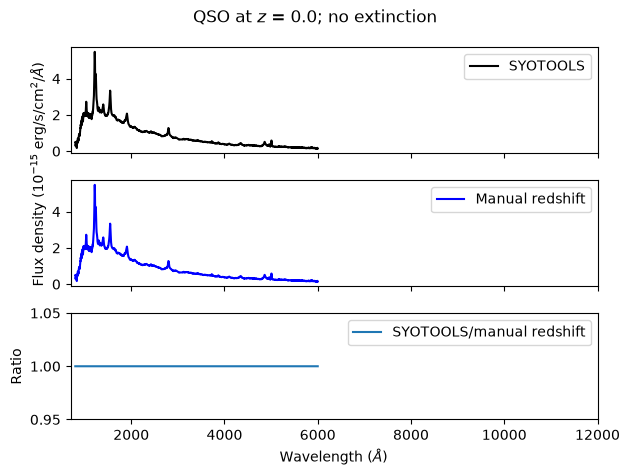

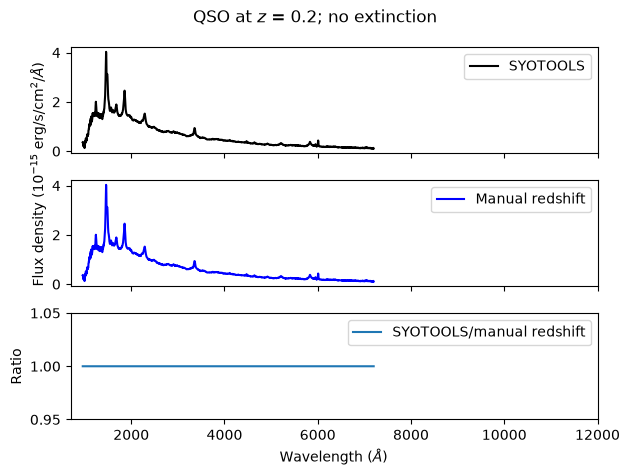

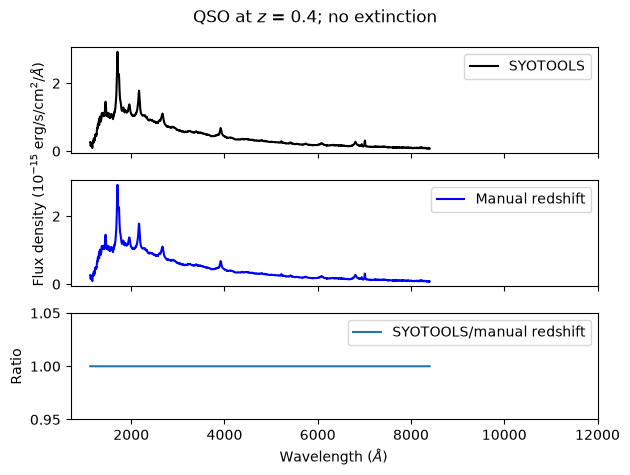

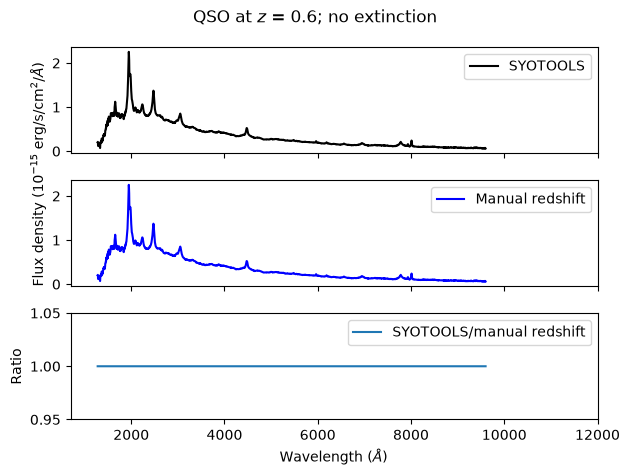

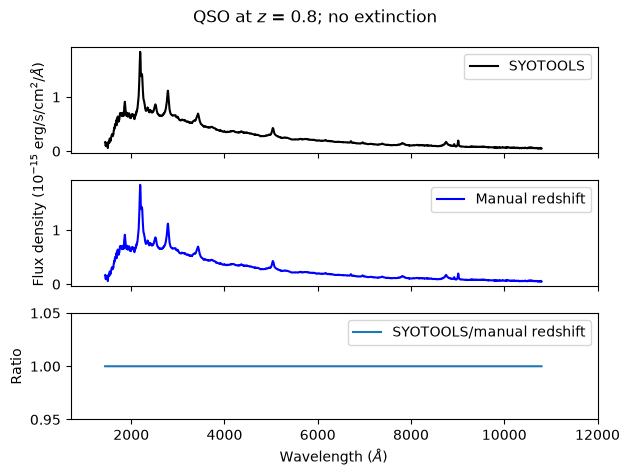

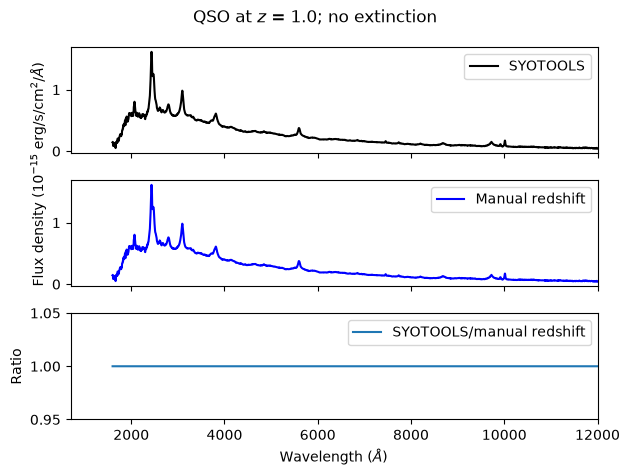

In [6]:
# Set up redshift array
z_arr = np.arange(0,1.1,0.2)

# Cycle through the redshift array
for z in z_arr:

    fig, axs = plt.subplots(3,sharex=True)
    fig.suptitle(r'QSO at $z$ = '+str(np.round(z,1)) + '; no extinction') 

    # Define and normalize SED in SYOTOOLS
    syotools_wave, \
    syotools_qso_flux_z = syotools_flam(sed,template,mag,z,extinction,bandpass)

    # Plot the SYOTOOLS SED
    axs[0].plot(syotools_wave, syotools_qso_flux_z*1e15, color='black', label='SYOTOOLS')
    axs[0].legend()
       
    # Manually redshift source, starting with the QSO SED defined at z = 0
    # Redshift wavelength axis:
    wave_z = qso_wave_rest*(1+z)
    # Create a spectrum class for this model, using the redshifted wavelength axis (i.e., wave_z)
    # and the input at SED at z=0 (i.e., qso_flux_rest)
    manual_qso_sed = syn.SourceSpectrum(syn.models.Empirical1D, 
                                        points=wave_z, 
                                        lookup_table=qso_flux_rest)
    # Normalize the spectrum to the specified magnitude and convert to flux density units
    manual_wave, \
    manual_qso_flux_z = norm_sed(manual_qso_sed, bandpass, mag)

    # Plot the SED that's manually redshifted
    axs[1].plot(manual_wave, manual_qso_flux_z*1e15, color='blue',
                label='Manual redshift')
    axs[1].set_ylabel(r'Flux density (10$^{-15}$ erg/s/cm$^2$/$\AA$)',loc='bottom')
    axs[1].legend()

    # Take the ratio of the two SEDs
    axs[2].plot(syotools_wave,syotools_qso_flux_z/manual_qso_flux_z,
                label='SYOTOOLS/manual redshift')
    axs[2].set_ylim(0.95,1.05)
    axs[2].set_ylabel('Ratio')
    axs[2].legend()
    axs[2].set_xlim(700,12000)
    axs[2].set_xlabel(r'Wavelength ($\AA$)')
    

    plt.tight_layout()

## Add Extinction

When applying extinction to an SED, SYOTOOLS assumes an average Milky Way extinction curve with R(V)=3.1 (the `mwavg` model from [synphot](https://synphot.readthedocs.io/en/latest/synphot/spectrum.html); [Cardelli et al. 1989](https://scixplorer.org/abs/1989ApJ...345..245C/abstract)). Note that extinction is parameterized by E(B-V).

To test the handling of extinction in SYOTOOLS, we will apply a range of E(B-V) values to the QSO template SED, ranging from 0.25 $<$ E(B-V) < 2.5 magnitudes which are ranges observed in red quasars, though the SMC extinction curve is a better fit to the observed data (e.g., [Glikman et al. 2007](https://scixplorer.org/abs/2007ApJ...667..673G/abstract), [Glikman et al. 2022](https://scixplorer.org/abs/2022ApJ...934..119G/abstract)). We will compare the SYOTOOLS SED at $z=0$ with that produced from manually adding extinction assuming the same `mwavg` model from `synphot`.


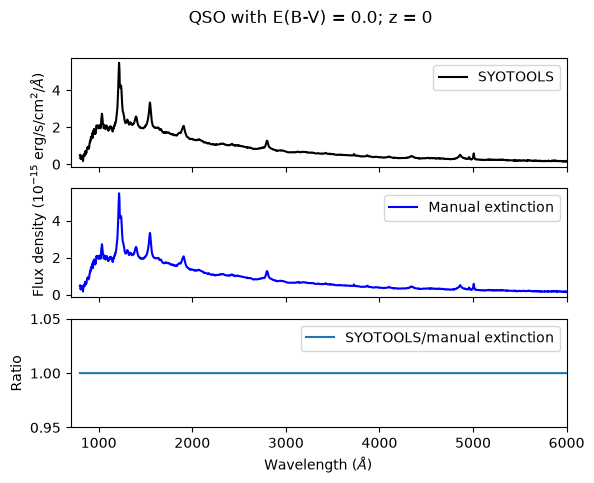

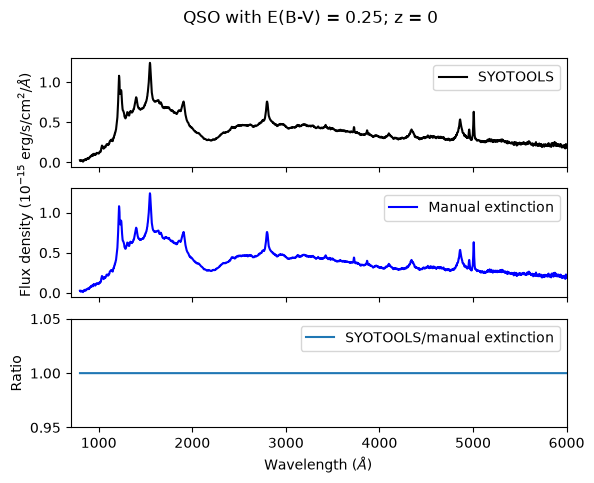

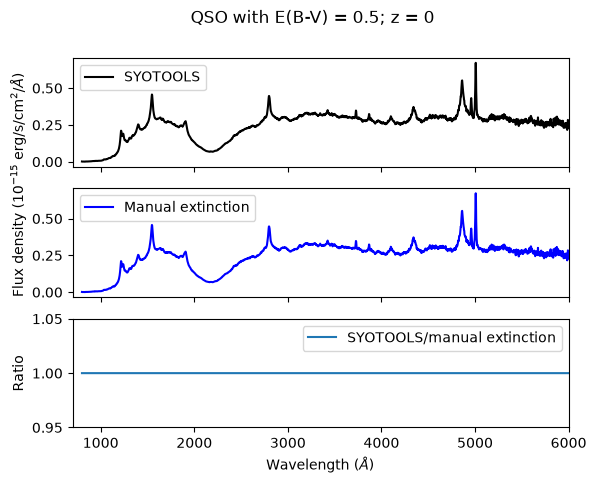

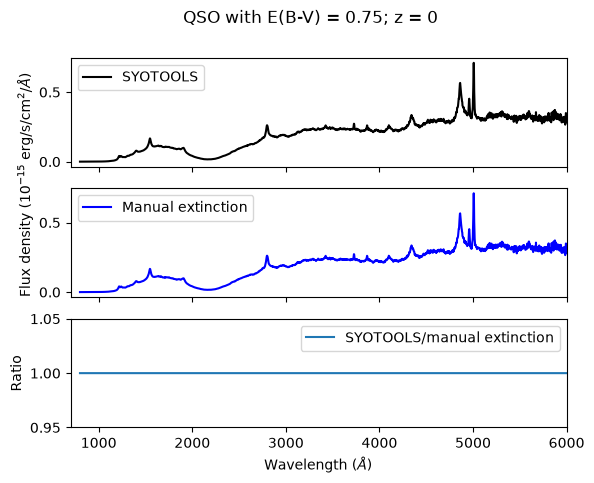

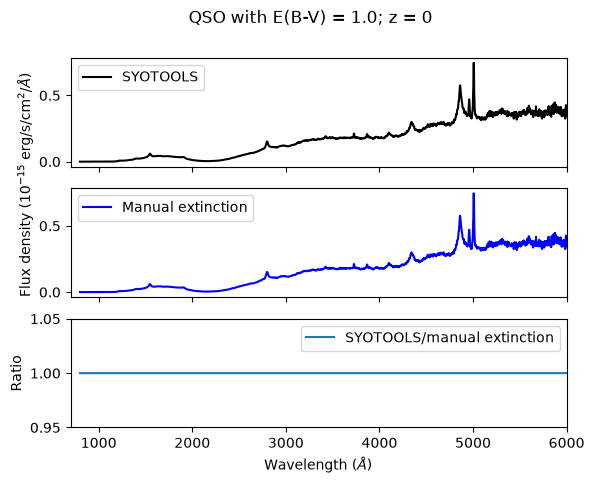

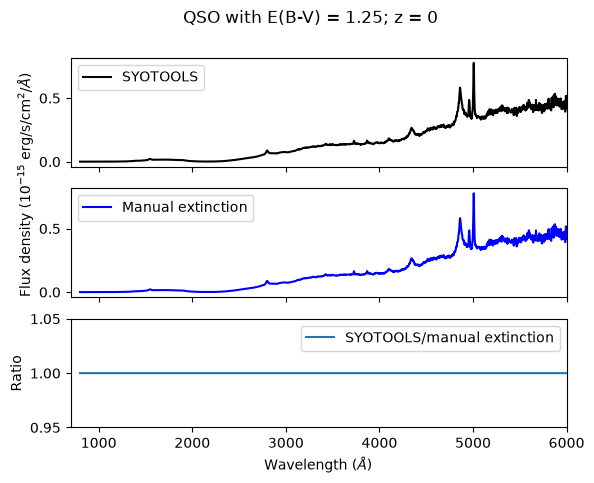

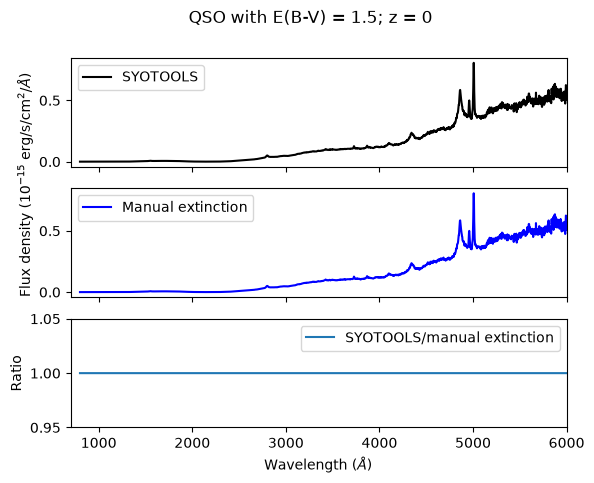

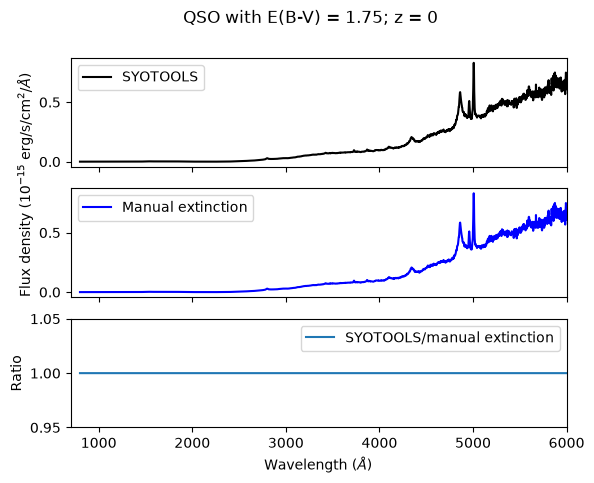

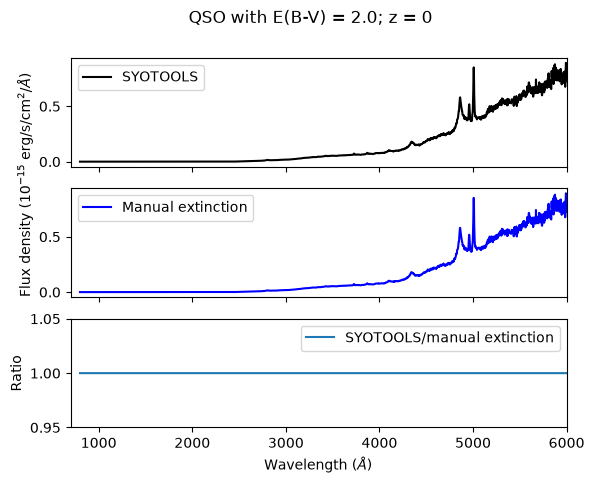

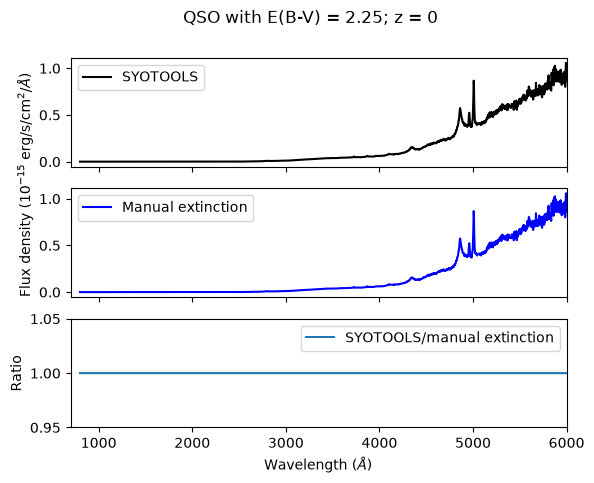

In [7]:
# Set up an array of E(B-V) values
ebv_arr = np.arange(0,2.5,0.25)
redshift = 0

# Cycle through through E(B-V) values
for ebv in ebv_arr:

    fig, axs = plt.subplots(3,sharex=True)
    fig.suptitle(r'QSO with E(B-V) = '+str(ebv) + '; z = 0') 

    # Define and normalize SED in SYOTOOLS
    syotools_wave, \
    syotools_qso_flux_ext = syotools_flam(sed,template,mag,redshift,ebv,bandpass)

    # Plot the SYOTOOLS SED
    axs[0].plot(syotools_wave, syotools_qso_flux_ext*1e15, color='black', label='SYOTOOLS')
    axs[0].legend()

    # Manually add extinction
    # Create a spectrum class for this model, using the input SED at z=0
    manual_qso_sed = syn.SourceSpectrum(syn.models.Empirical1D, points=qso_wave_rest, lookup_table=qso_flux_rest)
    # Add extinction
    mw_ext = syn.ReddeningLaw.from_extinction_model('mwavg').extinction_curve(ebv)
    # Multiply SED by the extinction curve
    sp_ext = manual_qso_sed * mw_ext
    # Normalize the spectrum to the specified magnitude and convert to flux density units
    manual_wave, \
    manual_qso_flux_ext = norm_sed(sp_ext, bandpass, mag)

    # Plot the SED with extinction added manually
    axs[1].plot(manual_wave, manual_qso_flux_ext*1e15, color='blue',
                label='Manual extinction')
    axs[1].set_ylabel(r'Flux density (10$^{-15}$ erg/s/cm$^2$/$\AA$)',loc='bottom')
    axs[1].legend()

    # Take the ratio of the two SEDs
    axs[2].plot(syotools_wave, syotools_qso_flux_ext/manual_qso_flux_ext,
                label='SYOTOOLS/manual extinction')
    axs[2].set_ylim(0.95,1.05)
    axs[2].set_ylabel('Ratio')
    axs[2].legend()
    axs[2].set_xlim(700,6000)
    axs[2].set_xlabel(r'Wavelength ($\AA$)')


## Add Extinction and Redshift the SED

Note that SYOTOOLS redshifts the wavelength axis of the input SED, applies extinction, and then normalized the SED. We'll follow that order of operations in this comparison when manually modifying the input SED.

To prevent this notebook from getting too long, let's do this for a handful of redshift and extinction values.

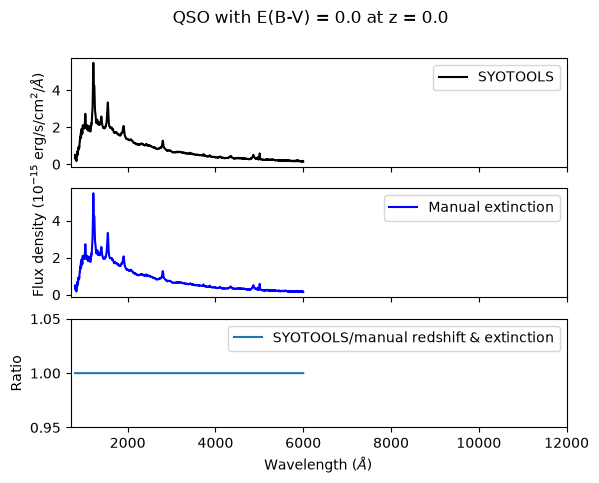

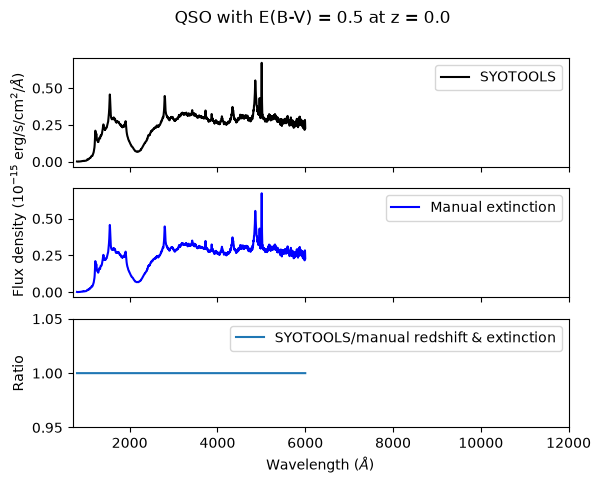

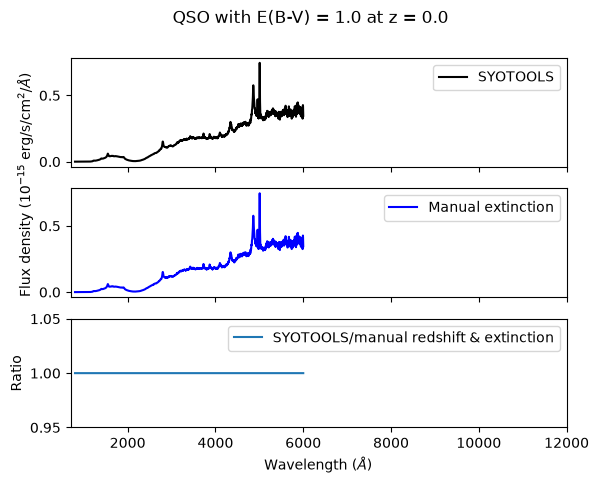

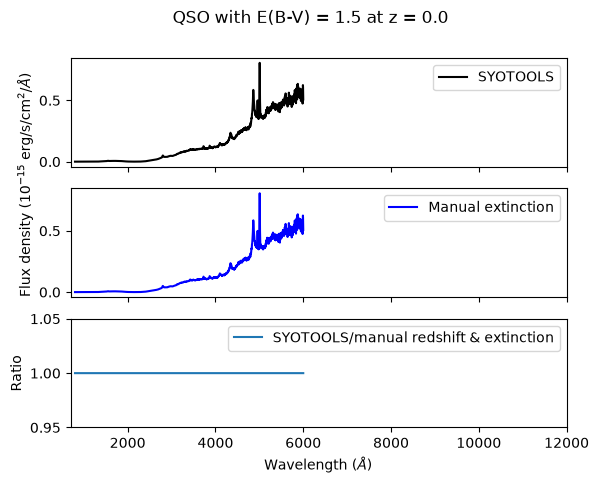

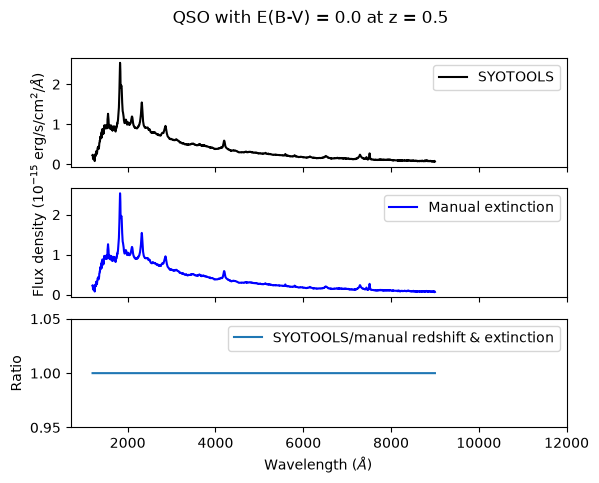

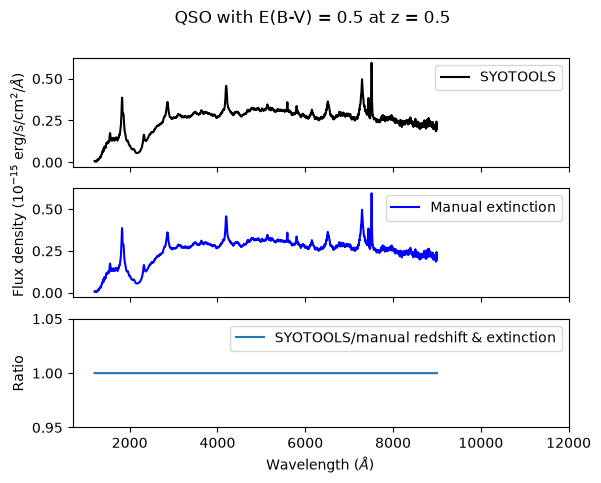

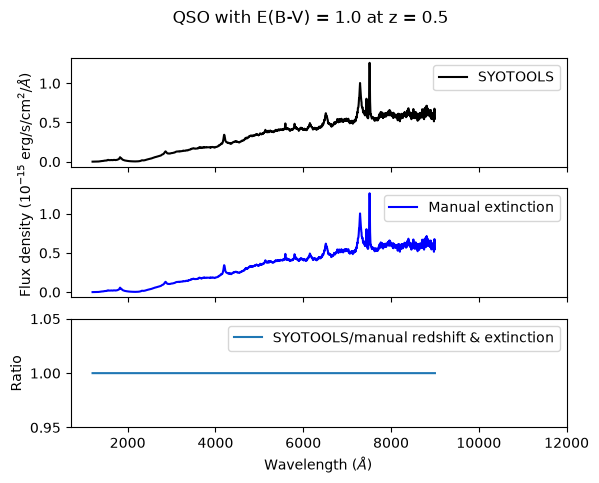

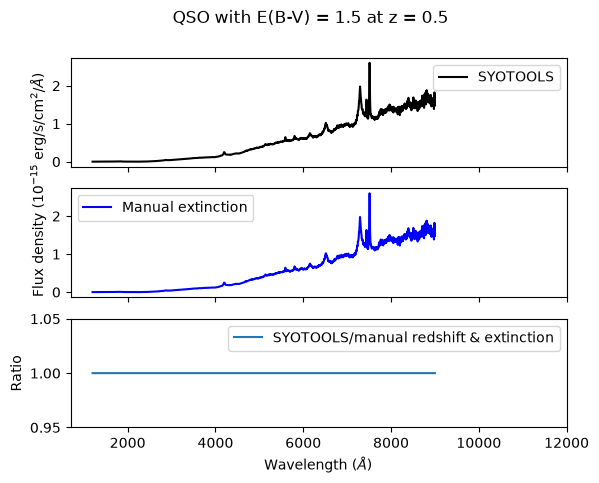

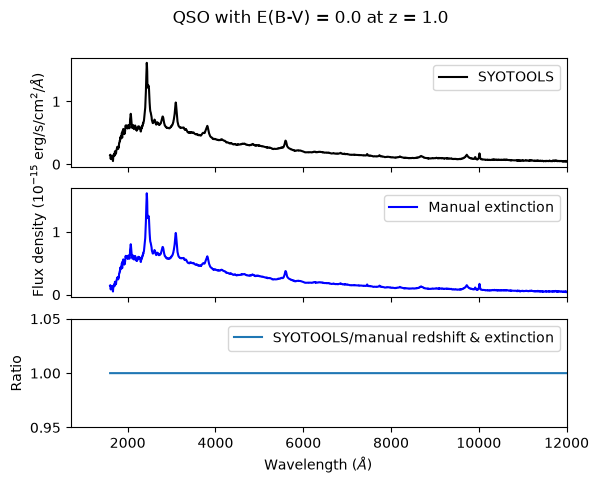

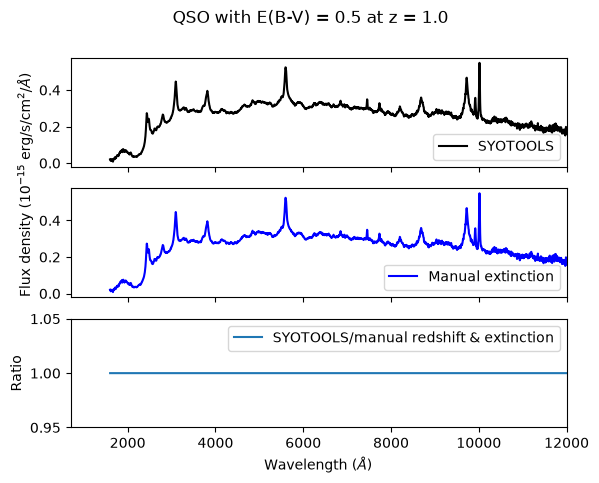

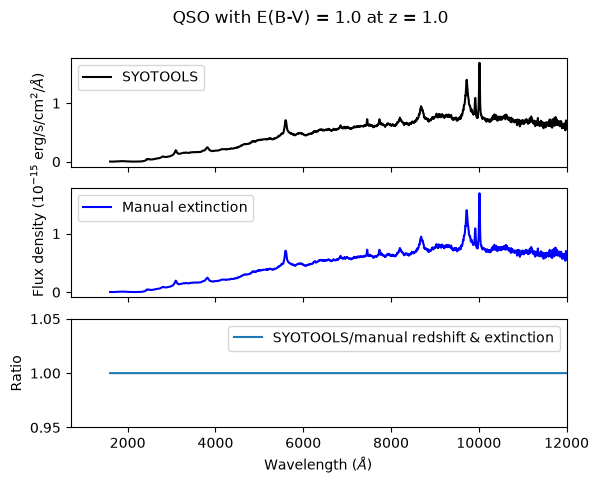

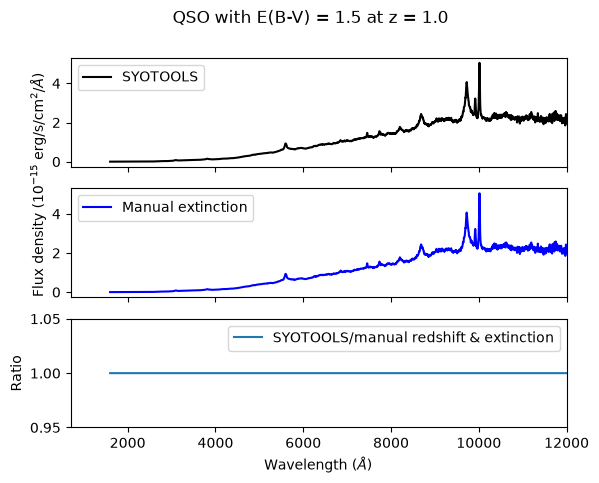

In [8]:
# Set up redshift array
z_arr = np.arange(0,1.1,0.5)

# Set up an array of E(B-V) values
ebv_arr = np.arange(0,1.6,0.5)

# Cycle through redshift
for z in z_arr:

    # Cycle through extinction
    for ebv in ebv_arr:

        fig, axs = plt.subplots(3,sharex=True)
        fig.suptitle(r'QSO with E(B-V) = '+str(ebv) + ' at z = '+str(np.round(z,1))) 

        # Define and normalize SED in SYOTOOLS
        syotools_wave, \
        syotools_qso_flux_ext_z = syotools_flam(sed,template,mag,z,ebv,bandpass)

        # Plot the SYOTOOLS SED
        axs[0].plot(syotools_wave, syotools_qso_flux_ext_z*1e15, color='black', label='SYOTOOLS')
        axs[0].legend()

        # Manually redshift source, starting with the QSO SED defined at z = 0
        # Redshift wavelength axis:
        wave_z = qso_wave_rest*(1+z)
        # Create a spectrum class for this model, using the redshifted wavelength axis (i.e., wave_z)
        # and the input at SED at z=0 (i.e., qso_flux_rest)
        manual_qso_sed = syn.SourceSpectrum(syn.models.Empirical1D, 
                                            points=wave_z, 
                                            lookup_table=qso_flux_rest)
        # Add extinction
        mw_ext = syn.ReddeningLaw.from_extinction_model('mwavg').extinction_curve(ebv)
        # Multiply SED by the extinction curve
        sp_ext = manual_qso_sed * mw_ext
        # Normalize the spectrum to the specified magnitude and convert to flux density units
        manual_wave, \
        manual_qso_flux_ext_z = norm_sed(sp_ext, bandpass, mag)

        # Plot the manually redshifted SED with extinction added manually
        axs[1].plot(manual_wave, manual_qso_flux_ext_z*1e15, color='blue',
                    label='Manual extinction')
        axs[1].set_ylabel(r'Flux density (10$^{-15}$ erg/s/cm$^2$/$\AA$)',loc='bottom')
        axs[1].legend()

        # Take the ratio of the two SEDs
        axs[2].plot(syotools_wave, syotools_qso_flux_ext_z/manual_qso_flux_ext_z,
                    label='SYOTOOLS/manual redshift & extinction')
        axs[2].set_ylim(0.95,1.05)
        axs[2].set_ylabel('Ratio')
        axs[2].legend()
        axs[2].set_xlim(700,12000)
        axs[2].set_xlabel(r'Wavelength ($\AA$)')
        
